# Analisis Sentimen Tweet Tayangan Televisi
**TF-IDF + Multinomial Naive Bayes**

## 1. Project Overview

**Latar belakang.** Tayangan televisi banyak dibicarakan penonton di Twitter. Tweet tersebut berisi opini yang bisa menunjukkan apakah sebuah acara disukai atau dikritik, tetapi membaca ratusan tweet secara manual tidak efisien.

**Tujuan.** Membangun model klasifikasi teks yang mengelompokkan tweet tentang tayangan TV menjadi sentimen **positif** atau **negatif**, menggunakan TF-IDF dan Multinomial Naive Bayes.

**Permasalahan.**
1. Bagaimana kondisi dan karakteristik dataset tweet tayangan TV?
2. Seberapa baik model sederhana (TF-IDF + Naive Bayes) membedakan tweet positif dan negatif?
3. Bagaimana sebaran sentimen pada tiap acara TV?

**Manfaat.** Hasil analisis sentimen dapat membantu stasiun TV dan tim produksi memantau respons penonton secara cepat, menemukan acara yang banyak dikritik, dan menjadi bahan evaluasi konten.

## 2. Import Library

In [ ]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                            classification_report, confusion_matrix)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
PALET = {'positive': '#2a9d8f', 'negative': '#e76f51'}   # warna konsisten untuk sentimen
RANDOM_STATE = 42

## 3. Memahami Dataset

In [2]:
# Path relatif; ubah jika file berada di folder lain (mis. '/content/' di Google Colab)
df = pd.read_csv('dataset_tweet_sentimen_tayangan_tv.csv', encoding='utf-8-sig')

print(f'Jumlah baris : {df.shape[0]}')
print(f'Jumlah kolom : {df.shape[1]}')
print('\nNama kolom   :', list(df.columns))
df.head()

Jumlah baris : 400
Jumlah kolom : 5

Nama kolom   : ['Id', 'Sentiment', 'Acara TV', 'Jumlah Retweet', 'Text Tweet']


,Id,Sentiment,Acara TV,Jumlah Retweet,Text Tweet
0,1,positive,HitamPutihTransTV,12,"Undang @N_ShaniJKT48 ke hitamputih, pemenang S..."
1,2,positive,HitamPutihTransTV,6,Selamat berbuka puasa Semoga amal ibadah hari ...
2,3,positive,HitamPutihTransTV,9,"Ada nih di trans7 hitam putih, dia dpt penghar..."
3,4,positive,HitamPutihTransTV,2,selamat ya mas @adietaufan masuk hitamputih
4,5,positive,HitamPutihTransTV,1,Asiknya nonton Hitam Putih Trans7


In [ ]:
print('Tipe data tiap kolom:')
print(df.dtypes)
print('\nMissing value per kolom:')
print(df.isnull().sum())
print(f'\nBaris duplikat (seluruh kolom) : {df.duplicated().sum()}')
print(f'Teks tweet duplikat              : {df["Text Tweet"].duplicated().sum()}')

Tipe data tiap kolom:
Id                int64
Sentiment           str
Acara TV            str
Jumlah Retweet    int64
Text Tweet          str
dtype: object

Missing value per kolom:
Id                0
Sentiment         0
Acara TV          0
Jumlah Retweet    0
Text Tweet        0
dtype: int64

Baris duplikat (seluruh kolom)  : 0
Teks tweet duplikat              : 0


In [4]:
print('Distribusi label Sentiment:')
print(df['Sentiment'].value_counts())
print('\nDistribusi tweet per Acara TV:')
print(df['Acara TV'].value_counts())
print('\nStatistik Jumlah Retweet:')
print(df['Jumlah Retweet'].describe().round(2))

Distribusi label Sentiment:
Sentiment
positive    200
negative    200
Name: count, dtype: int64

Distribusi tweet per Acara TV:
Acara TV
HitamPutihTransTV            100
IndonesiaLawyersClubTvOne    100
KickAndyMetroTV              100
MataNajwaMetroTV             100
Name: count, dtype: int64

Statistik Jumlah Retweet:
count    400.00
mean       3.58
std        4.88
min        0.00
25%        0.00
50%        2.00
75%        5.00
max       19.00
Name: Jumlah Retweet, dtype: float64


**Ringkasan eksplorasi**
- Dataset berisi **400 tweet** dengan **5 kolom** (`Id`, `Sentiment`, `Acara TV`, `Jumlah Retweet`, `Text Tweet`). Tidak ada missing value dan tidak ada data duplikat.
- Label **seimbang sempurna**: 200 positif dan 200 negatif. Setiap acara TV (Hitam Putih, ILC, Kick Andy, Mata Najwa) memiliki 100 tweet, masing-masing 50 positif dan 50 negatif.
- Jumlah retweet condong ke kanan: median 2, rata-rata 3,58, maksimum 19, dan setidaknya 25% tweet tidak pernah di-retweet.
- Karena kelas seimbang, accuracy masih layak dipakai, tetapi precision, recall, dan F1 tetap ditampilkan.

## 4. Exploratory Data Analysis

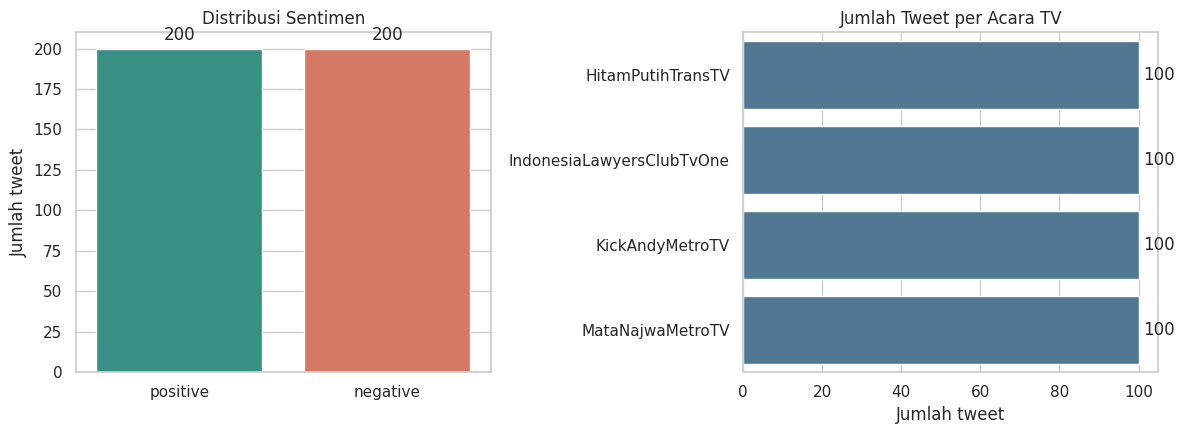

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Distribusi sentimen
ax = sns.countplot(data=df, x='Sentiment', order=['positive', 'negative'], palette=PALET, ax=axes[0])
ax.set_title('Distribusi Sentimen'); ax.set_xlabel(''); ax.set_ylabel('Jumlah tweet')
for c in ax.containers: ax.bar_label(c, padding=3)

# Distribusi tweet per acara
urut = df['Acara TV'].value_counts().index
ax = sns.countplot(data=df, y='Acara TV', order=urut, color='#457b9d', ax=axes[1])
ax.set_title('Jumlah Tweet per Acara TV'); ax.set_xlabel('Jumlah tweet'); ax.set_ylabel('')
for c in ax.containers: ax.bar_label(c, padding=3)

plt.tight_layout(); plt.show()

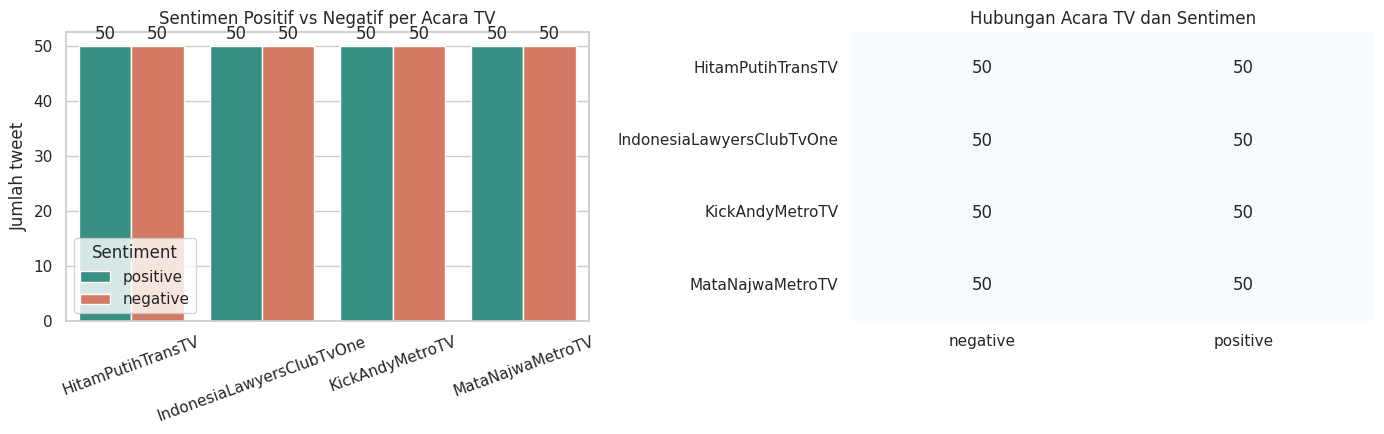

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Sentimen positif vs negatif pada tiap acara
ax = sns.countplot(data=df, x='Acara TV', hue='Sentiment', hue_order=['positive', 'negative'],
                   palette=PALET, ax=axes[0])
ax.set_title('Sentimen Positif vs Negatif per Acara TV'); ax.set_xlabel(''); ax.set_ylabel('Jumlah tweet')
ax.tick_params(axis='x', rotation=20)
for c in ax.containers: ax.bar_label(c, padding=2)

# Heatmap hubungan acara TV dan sentimen
tabel_silang = pd.crosstab(df['Acara TV'], df['Sentiment'])
sns.heatmap(tabel_silang, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1])
axes[1].set_title('Hubungan Acara TV dan Sentimen'); axes[1].set_xlabel(''); axes[1].set_ylabel('')

plt.tight_layout(); plt.show()

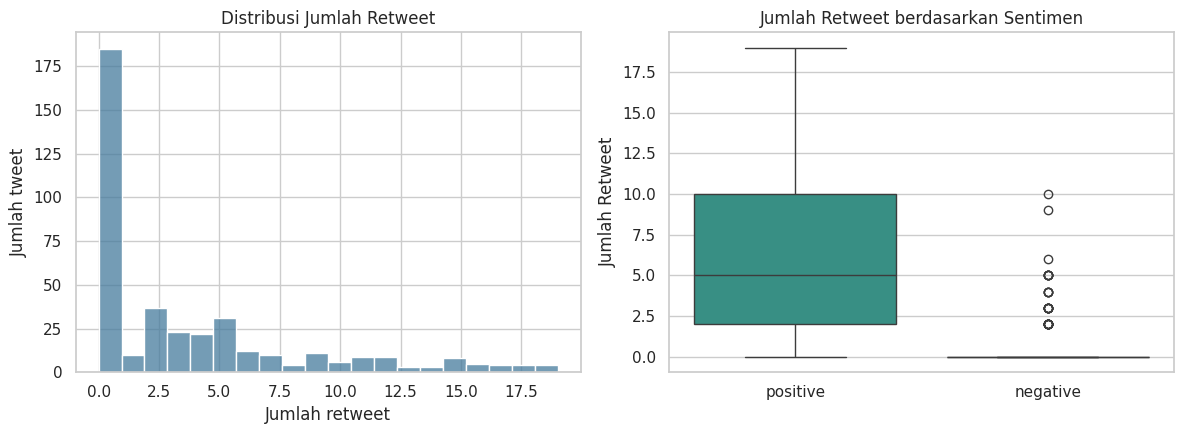

           mean  median  max
Sentiment                   
negative   0.60     0.0   10
positive   6.57     5.0   19


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df['Jumlah Retweet'], bins=20, color='#457b9d', ax=axes[0])
axes[0].set_title('Distribusi Jumlah Retweet'); axes[0].set_xlabel('Jumlah retweet'); axes[0].set_ylabel('Jumlah tweet')

sns.boxplot(data=df, x='Sentiment', y='Jumlah Retweet', order=['positive', 'negative'], palette=PALET, ax=axes[1])
axes[1].set_title('Jumlah Retweet berdasarkan Sentimen'); axes[1].set_xlabel('')

plt.tight_layout(); plt.show()

print(df.groupby('Sentiment')['Jumlah Retweet'].agg(['mean', 'median', 'max']).round(2))

**Temuan EDA**
- Sentimen dan jumlah tweet per acara terdistribusi merata, sehingga **perbedaan antar acara tidak dapat dibaca dari jumlah tweet**. Dataset tampaknya dikumpulkan dengan kuota yang sama untuk tiap acara dan label.
- Jumlah retweet sangat berbeda antar sentimen: tweet positif rata-rata **6,57 retweet** (median 5), tweet negatif hanya **0,60** (median 0). Pola ini konsisten di keempat acara. Retweet tidak dipakai sebagai fitur model karena tujuan project adalah mengklasifikasi dari isi teks, dan nilainya tidak tersedia saat memprediksi tweet baru yang belum beredar.

## 5. Text Preprocessing

Tahapan preprocessing: **case folding → hapus URL → hapus mention → hapus hashtag → hapus karakter non-huruf → tokenisasi → stopword removal**.

Catatan penting: kata negasi (`tidak`, `bukan`, `jangan`, `belum`, `gak`, `ga`) **sengaja dipertahankan** karena membawa makna sentimen ("tidak bagus" berbeda dengan "bagus").

In [8]:
# Stopword Bahasa Indonesia sederhana + kata umum domain TV.
# Kata negasi TIDAK dimasukkan agar informasi sentimen tidak hilang.
stopwords = set("""
yang dan di ke dari untuk dengan ini itu ada pada akan
saya kamu kita mereka acara sangat juga sudah lebih bisa dapat
jadi agar atau karena tentang dalam nya yg aku kau dia tv nonton
""".split())

def preprocessing(text):
    text = text.lower()                              # 1. case folding
    text = re.sub(r'http\S+|www\.\S+', ' ', text)     # 2. hapus URL
    text = re.sub(r'@\w+', ' ', text)                # 3. hapus mention
    text = re.sub(r'#\w+', ' ', text)                # 4. hapus hashtag (seluruh kata)
    text = re.sub(r'[^a-z\s]', ' ', text)            # 5. hapus angka, tanda baca, emoji
    tokens = text.split()                            # 6. tokenisasi
    tokens = [t for t in tokens if len(t) >= 2 and t not in stopwords]   # 7. stopword removal
    return ' '.join(tokens)

# Contoh tahap demi tahap pada satu tweet
contoh = df['Text Tweet'].iloc[0]
print('Asli    :', contoh)
print('Bersih  :', preprocessing(contoh))

Asli    : Undang @N_ShaniJKT48 ke hitamputih, pemenang SSK JKT48 harusnya mJKT48 ini lebih Layak di Undang karena prestasinya
Bersih  : undang hitamputih pemenang ssk jkt harusnya mjkt layak undang prestasinya


In [9]:
df['clean_text'] = df['Text Tweet'].apply(preprocessing)
df[['Text Tweet', 'clean_text']].sample(8, random_state=RANDOM_STATE)

,Text Tweet,clean_text
209,CARA GILA MENDAKI GUNUNG #KickAndy Luar Biasa ...,cara gila mendaki gunung luar biasa mantap jiwa
280,Orang Belanda aja peduli sama orang2 indonesia...,orang belanda aja peduli sama orang indonesia ...
33,Suka banget sama episode Hitam Putih malam ini...,suka banget sama episode hitam putih malam
210,sayangilah alam niscaya alam akan menyayangimu...,sayangilah alam niscaya alam menyayangimu
93,#hitamputiht7 apakah ada hal kaya gini di nega...,apakah hal kaya gini negara lain intinya gk se...
84,ga tau kenapa semua menjadi buruk ketika kau p...,ga tau kenapa semua menjadi buruk ketika pergi
329,"Tjokro dan rumahnya menjadi teladan, tentang s...",tjokro rumahnya menjadi teladan senioritas men...
94,"Gak punya Gadget, mahal, nipu / gk jelas argon...",gak punya gadget mahal nipu gk jelas argonya s...


In [10]:
# Pemeriksaan hasil preprocessing
print(f'Jumlah data sebelum preprocessing : {len(df)}')
teks_kosong = (df['clean_text'].str.strip() == '')
print(f'Teks kosong setelah preprocessing : {teks_kosong.sum()}')

df = df[~teks_kosong].reset_index(drop=True)      # buang teks kosong jika ada (aman jika 0)
print(f'Jumlah data sesudah preprocessing : {len(df)}')

df['jumlah_kata'] = df['clean_text'].str.split().str.len()
print('\nJumlah kata per tweet setelah dibersihkan:')
print(df['jumlah_kata'].describe().round(1))

Jumlah data sebelum preprocessing : 400
Teks kosong setelah preprocessing : 0
Jumlah data sesudah preprocessing : 400

Jumlah kata per tweet setelah dibersihkan:
count    400.0
mean       8.5
std        3.9
min        1.0
25%        5.0
50%        8.0
75%       11.0
max       19.0
Name: jumlah_kata, dtype: float64


In [11]:
# Kata paling sering muncul pada tiap kelas (sanity check hasil preprocessing)
from collections import Counter
for label in ['positive', 'negative']:
    kata = Counter(' '.join(df.loc[df['Sentiment'] == label, 'clean_text']).split())
    print(f'{label:8s}:', kata.most_common(10))

positive: [('putih', 32), ('hitam', 31), ('mata', 30), ('keren', 29), ('najwa', 29), ('trans', 16), ('pak', 15), ('banget', 13), ('malam', 13), ('menginspirasi', 13)]
negative: [('mata', 31), ('najwa', 31), ('orang', 25), ('ga', 24), ('tidak', 18), ('tdk', 15), ('aja', 14), ('indonesia', 14), ('pak', 14), ('anak', 13)]


**Hasil preprocessing**
- Jumlah data tetap **400** sebelum dan sesudah preprocessing, dan **tidak ada teks kosong**. Setelah dibersihkan, tweet rata-rata berisi sekitar 8-9 kata.
- Perbaikan dari versi awal: pola mention lama (`@\w+ `) hanya menghapus mention yang diikuti spasi, dan pola hashtag lama (`#\w`) hanya menghapus tanda `#` beserta satu huruf, sehingga sisa hashtag tertinggal. Keduanya diganti menjadi `@\w+` dan `#\w+`. Kata `tidak` juga dikeluarkan dari stopword karena merupakan negasi yang penting bagi sentimen.
- Kata paling sering muncul mengarah ke hal yang masuk akal (`keren`, `menginspirasi` pada kelas positif; `ga`, `tidak`, `tdk` pada kelas negatif). Nama acara (`hitam putih`, `mata najwa`) juga banyak muncul dan bisa ikut dipelajari model, ini dibahas pada analisis hasil.

## 6. Data Splitting

In [12]:
X = df['clean_text']
y = df['Sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f'Jumlah data training : {len(X_train)}')
print(f'Jumlah data testing  : {len(X_test)}')
print('\nDistribusi kelas data training:'); print(y_train.value_counts())
print('\nDistribusi kelas data testing:');  print(y_test.value_counts())

Jumlah data training : 320
Jumlah data testing  : 80

Distribusi kelas data training:
Sentiment
positive    160
negative    160
Name: count, dtype: int64

Distribusi kelas data testing:
Sentiment
negative    40
positive    40
Name: count, dtype: int64


`stratify=y` menjaga proporsi kelas positif/negatif tetap sama di data training dan testing, sehingga evaluasi tidak bias oleh pembagian data yang kebetulan timpang.

## 7. TF-IDF

**TF-IDF** (*Term Frequency – Inverse Document Frequency*) mengubah teks menjadi angka. Kata yang sering muncul di sebuah tweet tetapi jarang di tweet lain diberi bobot tinggi, sedangkan kata yang muncul di hampir semua tweet diberi bobot rendah. Dengan `ngram_range=(1,2)`, fitur mencakup kata tunggal dan pasangan dua kata (mis. "luar biasa"), sehingga sedikit konteks urutan kata ikut tertangkap.

Vectorizer hanya di-*fit* pada **data training**, lalu dipakai untuk men-*transform* data testing agar tidak terjadi *data leakage*.

In [13]:
tfidf = TfidfVectorizer(ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f'Bentuk matriks training : {X_train_tfidf.shape}')
print(f'Bentuk matriks testing  : {X_test_tfidf.shape}')
print(f'Jumlah fitur (unigram + bigram) : {len(tfidf.get_feature_names_out())}')

Bentuk matriks training : (320, 3564)
Bentuk matriks testing  : (80, 3564)
Jumlah fitur (unigram + bigram) : 3564


## 8. Model Training

Model utama adalah **Multinomial Naive Bayes**. Sebagai pembanding (baseline) digunakan **Logistic Regression** yang juga sederhana.

In [14]:
# Model utama
model_nb = MultinomialNB()
model_nb.fit(X_train_tfidf, y_train)
pred_nb = model_nb.predict(X_test_tfidf)

# Baseline pembanding
model_lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model_lr.fit(X_train_tfidf, y_train)
pred_lr = model_lr.predict(X_test_tfidf)

print('Training selesai untuk Multinomial Naive Bayes dan Logistic Regression.')

Training selesai untuk Multinomial Naive Bayes dan Logistic Regression.


## 9. Model Evaluation

In [15]:
def ringkas_metrik(nama, y_true, y_pred):
    return {
        'Model': nama,
        'Accuracy':  accuracy_score(y_true, y_pred),
        'Precision (macro)': precision_score(y_true, y_pred, average='macro'),
        'Recall (macro)':    recall_score(y_true, y_pred, average='macro'),
        'F1-score (macro)':  f1_score(y_true, y_pred, average='macro'),
    }

hasil = pd.DataFrame([ringkas_metrik('Multinomial Naive Bayes', y_test, pred_nb),
                      ringkas_metrik('Logistic Regression (baseline)', y_test, pred_lr)]).set_index('Model')
hasil.round(4)

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Multinomial Naive Bayes,0.8625,0.8627,0.8625,0.8625
Logistic Regression (baseline),0.8125,0.8292,0.8125,0.8101


In [16]:
print('Classification Report - Multinomial Naive Bayes')
print(classification_report(y_test, pred_nb, digits=3))

Classification Report - Multinomial Naive Bayes
              precision    recall  f1-score   support

    negative      0.854     0.875     0.864        40
    positive      0.872     0.850     0.861        40

    accuracy                          0.863        80
   macro avg      0.863     0.863     0.862        80
weighted avg      0.863     0.863     0.862        80



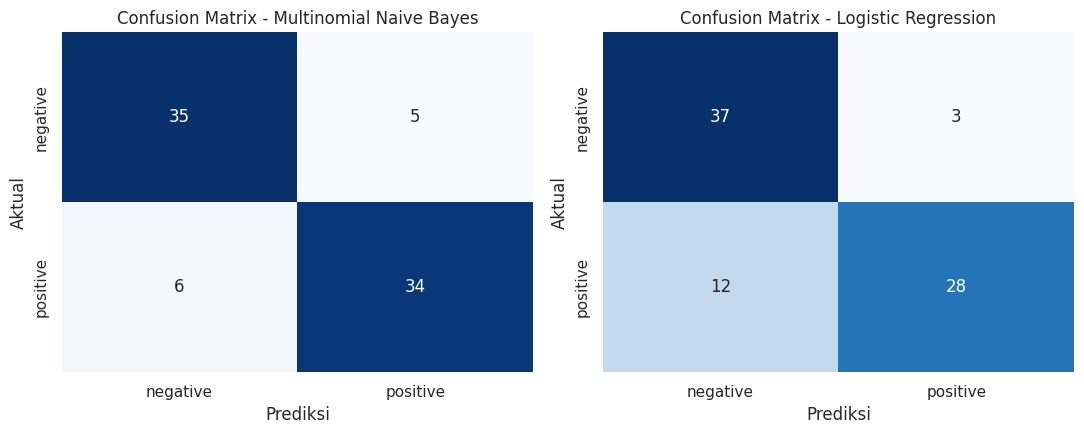

Naive Bayes -> benar negatif: 35, negatif salah jadi positif: 5, positif salah jadi negatif: 6, benar positif: 34


In [17]:
labels = ['negative', 'positive']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nama, pred) in zip(axes, [('Multinomial Naive Bayes', pred_nb), ('Logistic Regression', pred_lr)]):
    cm = confusion_matrix(y_test, pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f'Confusion Matrix - {nama}'); ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred_nb, labels=labels).ravel()
print(f'Naive Bayes -> benar negatif: {tn}, negatif salah jadi positif: {fp}, '
      f'positif salah jadi negatif: {fn}, benar positif: {tp}')

In [18]:
# Data testing hanya 80 tweet, sehingga hasil satu kali split bisa berfluktuasi.
# Cross-validation 5-fold pada seluruh data memberi gambaran yang lebih stabil.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pipe_nb = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), MultinomialNB())
pipe_lr = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

for nama, pipe in [('Multinomial Naive Bayes', pipe_nb), ('Logistic Regression', pipe_lr)]:
    skor = cross_val_score(pipe, X, y, cv=skf, scoring='f1_macro')
    print(f'{nama:25s} F1 macro 5-fold: {skor.mean():.3f} (+/- {skor.std():.3f})  | per fold: {skor.round(3)}')

Multinomial Naive Bayes   F1 macro 5-fold: 0.837 (+/- 0.025)  | per fold: [0.825 0.85  0.837 0.875 0.799]
Logistic Regression       F1 macro 5-fold: 0.829 (+/- 0.019)  | per fold: [0.836 0.862 0.825 0.81  0.812]


**Interpretasi evaluasi (data testing, 80 tweet)**
- **Naive Bayes** mencapai accuracy **86,25%** dan F1 macro **0,863**, lebih tinggi dari baseline Logistic Regression (accuracy 81,25%, F1 macro 0,810).
- Precision dan recall kedua kelas hampir sama (negatif: 0,854 / 0,875, positif: 0,872 / 0,850). Model tidak condong ke satu kelas.
- Pada confusion matrix, dari 80 tweet ada **69 prediksi benar** (35 negatif + 34 positif) dan **11 salah** (5 negatif diprediksi positif, 6 positif diprediksi negatif).
- Cross-validation 5-fold memberi F1 macro **0,837 (+/- 0,025)** untuk Naive Bayes dan **0,829 (+/- 0,019)** untuk Logistic Regression. Selisih kedua model pada cross-validation jauh lebih kecil dibanding pada satu kali split, jadi keunggulan Naive Bayes sebaiknya tidak dianggap pasti. Angka cross-validation lebih mewakili performa umum model dibanding angka satu kali split.

### Analisis Kesalahan Klasifikasi

In [19]:
analisis = pd.DataFrame({'Text Tweet': df.loc[X_test.index, 'Text Tweet'],
                         'Acara TV': df.loc[X_test.index, 'Acara TV'],
                         'Aktual': y_test, 'Prediksi': pred_nb})
salah = analisis[analisis['Aktual'] != analisis['Prediksi']]
print(f'Jumlah tweet salah prediksi: {len(salah)} dari {len(analisis)}\n')
pd.set_option('display.max_colwidth', 120)
salah.sort_values('Aktual')

Jumlah tweet salah prediksi: 11 dari 80



,Text Tweet,Acara TV,Aktual,Prediksi
392,"Tdk cukup dg menonton saja, km harus masuk kedalamnya untuk melakukan perubahan Ahok MataNajwaMetroTV",MataNajwaMetroTV,negative,positive
150,Yang di tunggu bukan tvshow tapi INDONESIA LAWYERS CLUB. TVshow tidak cocok dengan karakter siaran tvone!,IndonesiaLawyersClubTvOne,negative,positive
252,Lebih baik menyalakan lilin daripada mengumpat kepada kegelapan #pejuangtangguh #kickandy,KickAndyMetroTV,negative,positive
284,demi apapun ya kick andy sekarang botak? #kickandymetrotv,KickAndyMetroTV,negative,positive
253,"aku ga mau bohongi diri sendiri. Gimbal Alas, Malang. #kickandy",KickAndyMetroTV,negative,positive
10,cinta mengikat silaturahmi di hati ... #LunaMaya #hitamputihtrans7 .... https://www.instagram.com/p/BTqszJ3jO9A/,HitamPutihTransTV,positive,negative
321,semoga bapak jokowi melihat acara mata najwa supaya masalah masalah yg dipelosok dapat diatasi,MataNajwaMetroTV,positive,negative
203,Kickandy gokil #kickandy,KickAndyMetroTV,positive,negative
349,Cie yg lg ada job di @MataNajwa,MataNajwaMetroTV,positive,negative
215,Jatuh lalu bangkit Untuk membantu sesama #Kickandy,KickAndyMetroTV,positive,negative


**Analisis hasil**
- **Apakah model cukup baik?** Untuk model sederhana pada data hanya 400 tweet, ya: sekitar 84-86% tweet ditebak benar dan kedua kelas diperlakukan setara. Artinya dari setiap 100 tweet, sekitar 14-16 diberi label sentimen yang salah, sehingga hasilnya cocok untuk gambaran umum tetapi belum untuk keputusan per tweet.
- **Kelas mana yang lebih mudah?** Hampir sama. Pada data testing negatif sedikit lebih mudah (recall 0,875 vs 0,850), tetapi selisih satu tweet dari 40 terlalu kecil untuk disimpulkan.
- **Pola kesalahan.** Tweet negatif yang salah diprediksi positif umumnya bernada sindiran atau tidak memuat kata negatif eksplisit, misalnya "Lebih baik menyalakan lilin daripada mengumpat kepada kegelapan" atau "Yang di tunggu bukan tvshow tapi INDONESIA LAWYERS CLUB". Tweet positif yang salah diprediksi negatif umumnya pendek dan tanpa kata opini jelas, misalnya "Cie yg lg ada job di @MataNajwa" atau "Kickandy gokil".
- **Kemungkinan penyebab.** (1) Bag-of-words tidak memahami sindiran, konteks, maupun urutan kata yang panjang. (2) Kata slang dan singkatan (`gokil`, `tdk`, `gk`) belum dinormalisasi, dan sebagian jarang muncul sehingga bobotnya lemah. (3) Teks sangat pendek memberi sedikit fitur. (4) Data kecil membuat banyak kata hanya muncul sekali. (5) Nama acara muncul di banyak tweet dan dapat ikut dipelajari sebagai fitur, padahal bukan penanda sentimen. Poin terakhir adalah dugaan dari pola kata, belum diuji.

## 10. Analisis Sentimen Berdasarkan Acara TV

In [20]:
jumlah = pd.crosstab(df['Acara TV'], df['Sentiment'])
persen = (pd.crosstab(df['Acara TV'], df['Sentiment'], normalize='index') * 100).round(1)

print('Jumlah tweet per sentimen:');  display(jumlah)
print('Persentase sentimen (%):');    display(persen)

# Penanganan seri: gunakan seluruh acara yang memiliki nilai maksimum
for label in ['positive', 'negative']:
    maks = jumlah[label].max()
    pemenang = jumlah.index[jumlah[label] == maks].tolist()
    print(f'Sentimen {label:8s} terbanyak ({maks} tweet): {", ".join(pemenang)}')

Jumlah tweet per sentimen:


Sentiment,negative,positive
Acara TV,,
HitamPutihTransTV,50,50
IndonesiaLawyersClubTvOne,50,50
KickAndyMetroTV,50,50
MataNajwaMetroTV,50,50


Persentase sentimen (%):


Sentiment,negative,positive
Acara TV,,
HitamPutihTransTV,50.0,50.0
IndonesiaLawyersClubTvOne,50.0,50.0
KickAndyMetroTV,50.0,50.0
MataNajwaMetroTV,50.0,50.0


Sentimen positive terbanyak (50 tweet): HitamPutihTransTV, IndonesiaLawyersClubTvOne, KickAndyMetroTV, MataNajwaMetroTV


Sentimen negative terbanyak (50 tweet): HitamPutihTransTV, IndonesiaLawyersClubTvOne, KickAndyMetroTV, MataNajwaMetroTV


In [21]:
# Rata-rata retweet per acara dan sentimen
rata_rt = df.pivot_table(index='Acara TV', columns='Sentiment', values='Jumlah Retweet', aggfunc='mean').round(2)
print('Rata-rata Jumlah Retweet:'); display(rata_rt)

# Prediksi out-of-fold (setiap tweet diprediksi oleh model yang tidak pernah melihatnya saat training)
df['prediksi_cv'] = cross_val_predict(pipe_nb, X, y, cv=skf)
akurasi_acara = (df['prediksi_cv'] == df['Sentiment']).groupby(df['Acara TV']).mean().mul(100).round(1)
print('Akurasi model (cross-validation) per acara TV (%):'); display(akurasi_acara)

Rata-rata Jumlah Retweet:


Sentiment,negative,positive
Acara TV,,
HitamPutihTransTV,0.92,6.10
IndonesiaLawyersClubTvOne,0.46,7.10
KickAndyMetroTV,0.64,6.62
MataNajwaMetroTV,0.36,6.46


Akurasi model (cross-validation) per acara TV (%):


Acara TV
HitamPutihTransTV            87.0
IndonesiaLawyersClubTvOne    87.0
KickAndyMetroTV              77.0
MataNajwaMetroTV             84.0
dtype: float64

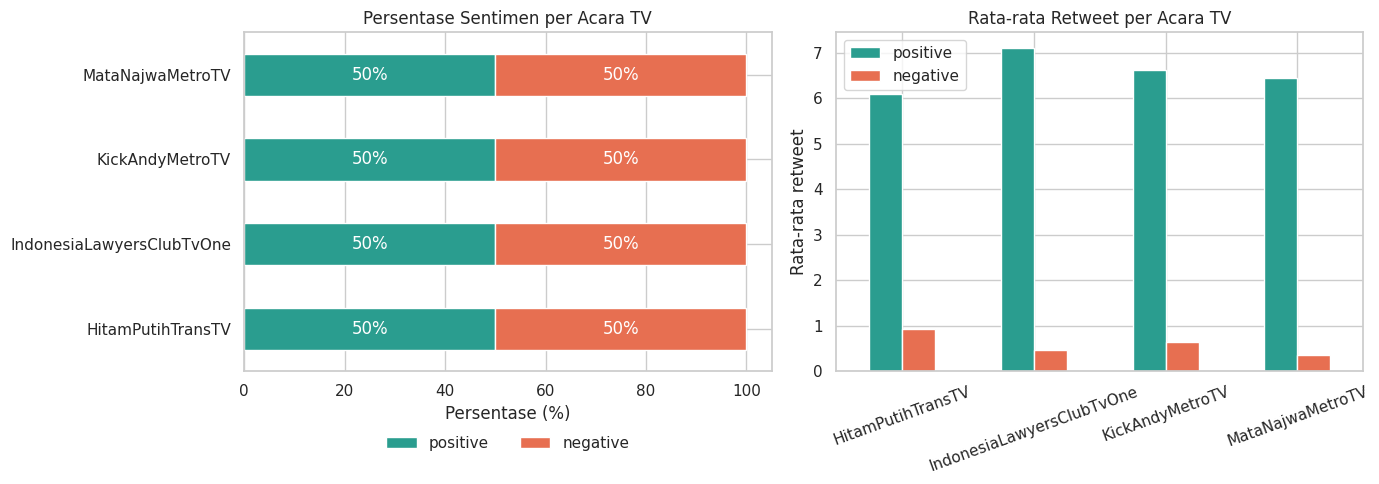

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Persentase sentimen per acara (stacked)
persen[['positive', 'negative']].plot(kind='barh', stacked=True, color=[PALET['positive'], PALET['negative']], ax=axes[0])
axes[0].set_title('Persentase Sentimen per Acara TV'); axes[0].set_xlabel('Persentase (%)'); axes[0].set_ylabel('')
for c in axes[0].containers: axes[0].bar_label(c, label_type='center', color='white', fmt='%.0f%%')
axes[0].legend(title='', loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)

# Rata-rata retweet per acara dan sentimen
rata_rt[['positive', 'negative']].plot(kind='bar', color=[PALET['positive'], PALET['negative']], ax=axes[1])
axes[1].set_title('Rata-rata Retweet per Acara TV'); axes[1].set_xlabel(''); axes[1].set_ylabel('Rata-rata retweet')
axes[1].tick_params(axis='x', rotation=20); axes[1].legend(title='')

plt.tight_layout(); plt.show()

**Temuan per acara TV**
- Pada dataset ini setiap acara memiliki **50 tweet positif dan 50 negatif (50% : 50%)**, sehingga **tidak ada acara dengan sentimen positif atau negatif terbanyak**; hasilnya seri untuk keempat acara. Ini akibat dataset yang dikumpulkan seimbang, bukan temuan tentang kualitas acara. Perbandingan kepuasan antar acara tidak bisa disimpulkan dari data ini; untuk itu diperlukan sampel tweet yang diambil secara acak.
- Perbedaan antar acara hanya terlihat pada rata-rata retweet tweet positif: ILC tertinggi (7,10), Hitam Putih terendah (6,10), dan selisih ini kecil. Pada tweet negatif, rata-rata retweet berkisar 0,36 (Mata Najwa) sampai 0,92 (Hitam Putih).
- Akurasi model (prediksi out-of-fold) per acara: Hitam Putih 87%, ILC 87%, Mata Najwa 84%, Kick Andy 77%. Tweet Kick Andy paling sulit diprediksi. Dalam analisis kesalahan di atas, 5 dari 11 salah prediksi pada data testing berasal dari Kick Andy; tweet-nya cenderung bernada reflektif atau kutipan (mis. "Jatuh lalu bangkit untuk membantu sesama"), yang sentimennya tersirat. Tiap acara hanya terdiri dari 100 tweet, jadi selisih beberapa poin persen belum tentu bermakna.

## 11. Contoh Prediksi Tweet Baru

In [23]:
# Model final: TF-IDF + Naive Bayes yang dilatih pada data training (sama seperti evaluasi di atas)
def prediksi_tweet(teks):
    bersih = preprocessing(teks)
    if bersih == '':
        return {'tweet': teks, 'sentimen': None, 'confidence': None,
                'catatan': 'Teks kosong setelah preprocessing, prediksi tidak dapat dilakukan.'}
    vektor = tfidf.transform([bersih])
    proba = model_nb.predict_proba(vektor)[0]
    idx = proba.argmax()
    return {'tweet': teks, 'sentimen': model_nb.classes_[idx], 'confidence': round(float(proba[idx]) * 100, 1)}

def prediksi_interaktif():
    teks = input('Masukkan tweet: ')
    hasil = prediksi_tweet(teks)
    if hasil['sentimen'] is None:
        print(hasil['catatan'])
    else:
        print(f"Prediksi sentimen: {hasil['sentimen']} (confidence {hasil['confidence']}%)")

# prediksi_interaktif()   # <- hapus tanda '#' untuk mencoba input manual

contoh_tweet = [
    'Acaranya bagus banget, narasumbernya inspiratif #MataNajwa',
    'Bosan, pembawa acaranya menyebalkan dan tidak berbobot',
    'Kick Andy selalu memberi motivasi, terima kasih',
    'Debat ILC makin tidak jelas, cuma ribut dan buang waktu',
]
pd.DataFrame([prediksi_tweet(t) for t in contoh_tweet])[['tweet', 'sentimen', 'confidence']]

,tweet,sentimen,confidence
0,"Acaranya bagus banget, narasumbernya inspiratif #MataNajwa",positive,71.7
1,"Bosan, pembawa acaranya menyebalkan dan tidak berbobot",negative,64.9
2,"Kick Andy selalu memberi motivasi, terima kasih",positive,84.5
3,"Debat ILC makin tidak jelas, cuma ribut dan buang waktu",negative,62.5


Fungsi `prediksi_tweet()` memakai preprocessing yang sama dengan data training, lalu menampilkan sentimen dan *confidence* dari `predict_proba`. Untuk input manual, aktifkan baris `prediksi_interaktif()`. Baris itu dinonaktifkan agar notebook dapat dijalankan otomatis dari awal sampai akhir.

Perlu diingat bahwa confidence Naive Bayes cenderung kurang terkalibrasi dan hanya menunjukkan kecenderungan relatif, bukan peluang sebenarnya. Nilainya di kisaran 62-85% pada contoh di atas menunjukkan model tidak terlalu yakin.

## 12. Kesimpulan

Berdasarkan hasil yang diperoleh dari notebook ini:

1. **Dataset.** 400 tweet, 4 acara TV, label seimbang (200 positif, 200 negatif; 50:50 pada setiap acara). Tidak ditemukan missing value, duplikat, maupun teks kosong setelah preprocessing.
2. **Preprocessing.** Pola penghapusan mention dan hashtag diperbaiki, dan kata negasi dipertahankan agar makna sentimen tidak hilang.
3. **Performa model.** TF-IDF (unigram + bigram) dengan Multinomial Naive Bayes mencapai accuracy **86,25%** dan F1 macro **0,863** pada data testing (80 tweet), serta F1 macro **0,837** pada cross-validation 5-fold. Kedua kelas diprediksi dengan kualitas yang hampir sama.
4. **Pembanding.** Logistic Regression memperoleh F1 macro 0,810 pada data testing dan 0,829 pada cross-validation. Naive Bayes sedikit unggul, tetapi selisihnya tipis pada cross-validation.
5. **Kesalahan.** Sebagian besar kesalahan terjadi pada tweet bernada sindiran, reflektif, atau sangat pendek, yaitu kasus yang sulit ditangani pendekatan bag-of-words.
6. **Analisis per acara.** Karena data seimbang, tidak ada acara dengan sentimen yang lebih dominan. Perbedaan kepuasan antar acara tidak dapat disimpulkan dari dataset ini.
7. **Keterbatasan.** Data kecil, hanya dua kelas, dan hasil bisa berbeda pada tweet dari periode atau acara lain. Karena itu, model ini lebih tepat dipandang sebagai demonstrasi alur analisis sentimen daripada alat yang siap dipakai di lapangan.

## 13. Future Improvement

1. **Menambah jumlah data.** 400 tweet tergolong kecil. Data lebih banyak dan lebih beragam membuat model lebih stabil dan evaluasi lebih dapat dipercaya.
2. **Normalisasi kata slang dan singkatan** (mis. `gak/ga/nggak` → `tidak`, `bgt` → `banget`, `yg` → `yang`) serta penanganan huruf berulang (`kereeen` → `keren`).
3. **Membandingkan beberapa algoritma** seperti Linear SVM, Random Forest, atau Complement Naive Bayes, dengan metrik dan cross-validation yang sama.
4. **Hyperparameter tuning** (mis. `alpha` pada Naive Bayes, `min_df`, `ngram_range`) menggunakan `GridSearchCV`.
5. **Menambah kelas netral** agar lebih mendekati kondisi nyata, karena banyak tweet tidak bernada jelas positif maupun negatif.
6. **Menyimpan model dan TF-IDF vectorizer** dengan `joblib` agar tidak perlu training ulang.
7. **Deploy sebagai aplikasi Streamlit** sehingga pengguna dapat memasukkan tweet dan melihat prediksi serta confidence secara langsung.